# Do family scores change before UCL episodes, and do they provide useful warning?

Retrospective matched trajectories complement the predictive matrix. Calendar-time and appearance-time alignment answer different questions.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
while not (ROOT/'src/injury_analysis').exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.injury_analysis.ucl_temporal_common import OUT, CACHE, read_table
pd.set_option('display.max_columns',24)
def show(name,n=30): display(read_table(name).head(n))
def plot(name): display(Image(filename=str(OUT/'figures'/(name+'.png')),width=1150))


In [2]:
from src.injury_analysis.ucl_temporal_trajectories import run_trajectories
run_trajectories()
show('trajectory_score_scales',n=12)
show('appearance_calendar_support',n=30)

Verified checkpoint: trajectories


,family,mean,sd,training_rows,training_max_date
0,Appearance performance,-4.904975,0.171618,64646,2021-10-03 00:00:00
1,Extension,-4.982893,0.492754,64646,2021-10-03 00:00:00
2,Location and strike fractions,-4.955313,0.370866,64646,2021-10-03 00:00:00
3,Pitch mix and pitch-type counts,-5.085738,0.770300,64646,2021-10-03 00:00:00
4,Pitch movement,-5.086855,0.642419,64646,2021-10-03 00:00:00
5,Pitcher background and experience,-5.172458,0.836267,64646,2021-10-03 00:00:00
6,Release position and variability,-5.101032,0.713359,64646,2021-10-03 00:00:00
7,Role and recent starts,-4.961067,0.401271,64646,2021-10-03 00:00:00
8,Spin,-4.960833,0.464400,64646,2021-10-03 00:00:00
9,Velocity,-5.247610,1.110177,64646,2021-10-03 00:00:00


,event_partition,kind,is_starter,outing_bin,rows,events,median_lead_days,minimum_lead_days,maximum_lead_days
0,test,Control,False,11+,22,4,49.0,28,60
1,test,Control,False,2–3,18,10,7.5,2,15
2,test,Control,False,4–5,20,11,15.5,6,41
3,test,Control,False,6–10,42,11,29.5,13,59
4,test,Control,False,Final,7,7,1.0,1,2
5,test,Control,True,11+,2,2,58.5,58,59
6,test,Control,True,2–3,26,14,10.5,6,18
7,test,Control,True,4–5,24,13,22.0,17,30
8,test,Control,True,6–10,38,11,40.5,28,60
9,test,Control,True,Final,15,15,1.0,1,7


Each family uses a single training-derived 60-day logistic score at every plotted time point, standardized by its training log-odds mean/SD. This avoids changing the score definition as the event approaches. Original matched controls are reused. Injury events and controls contribute equal weight after within-bin averaging.

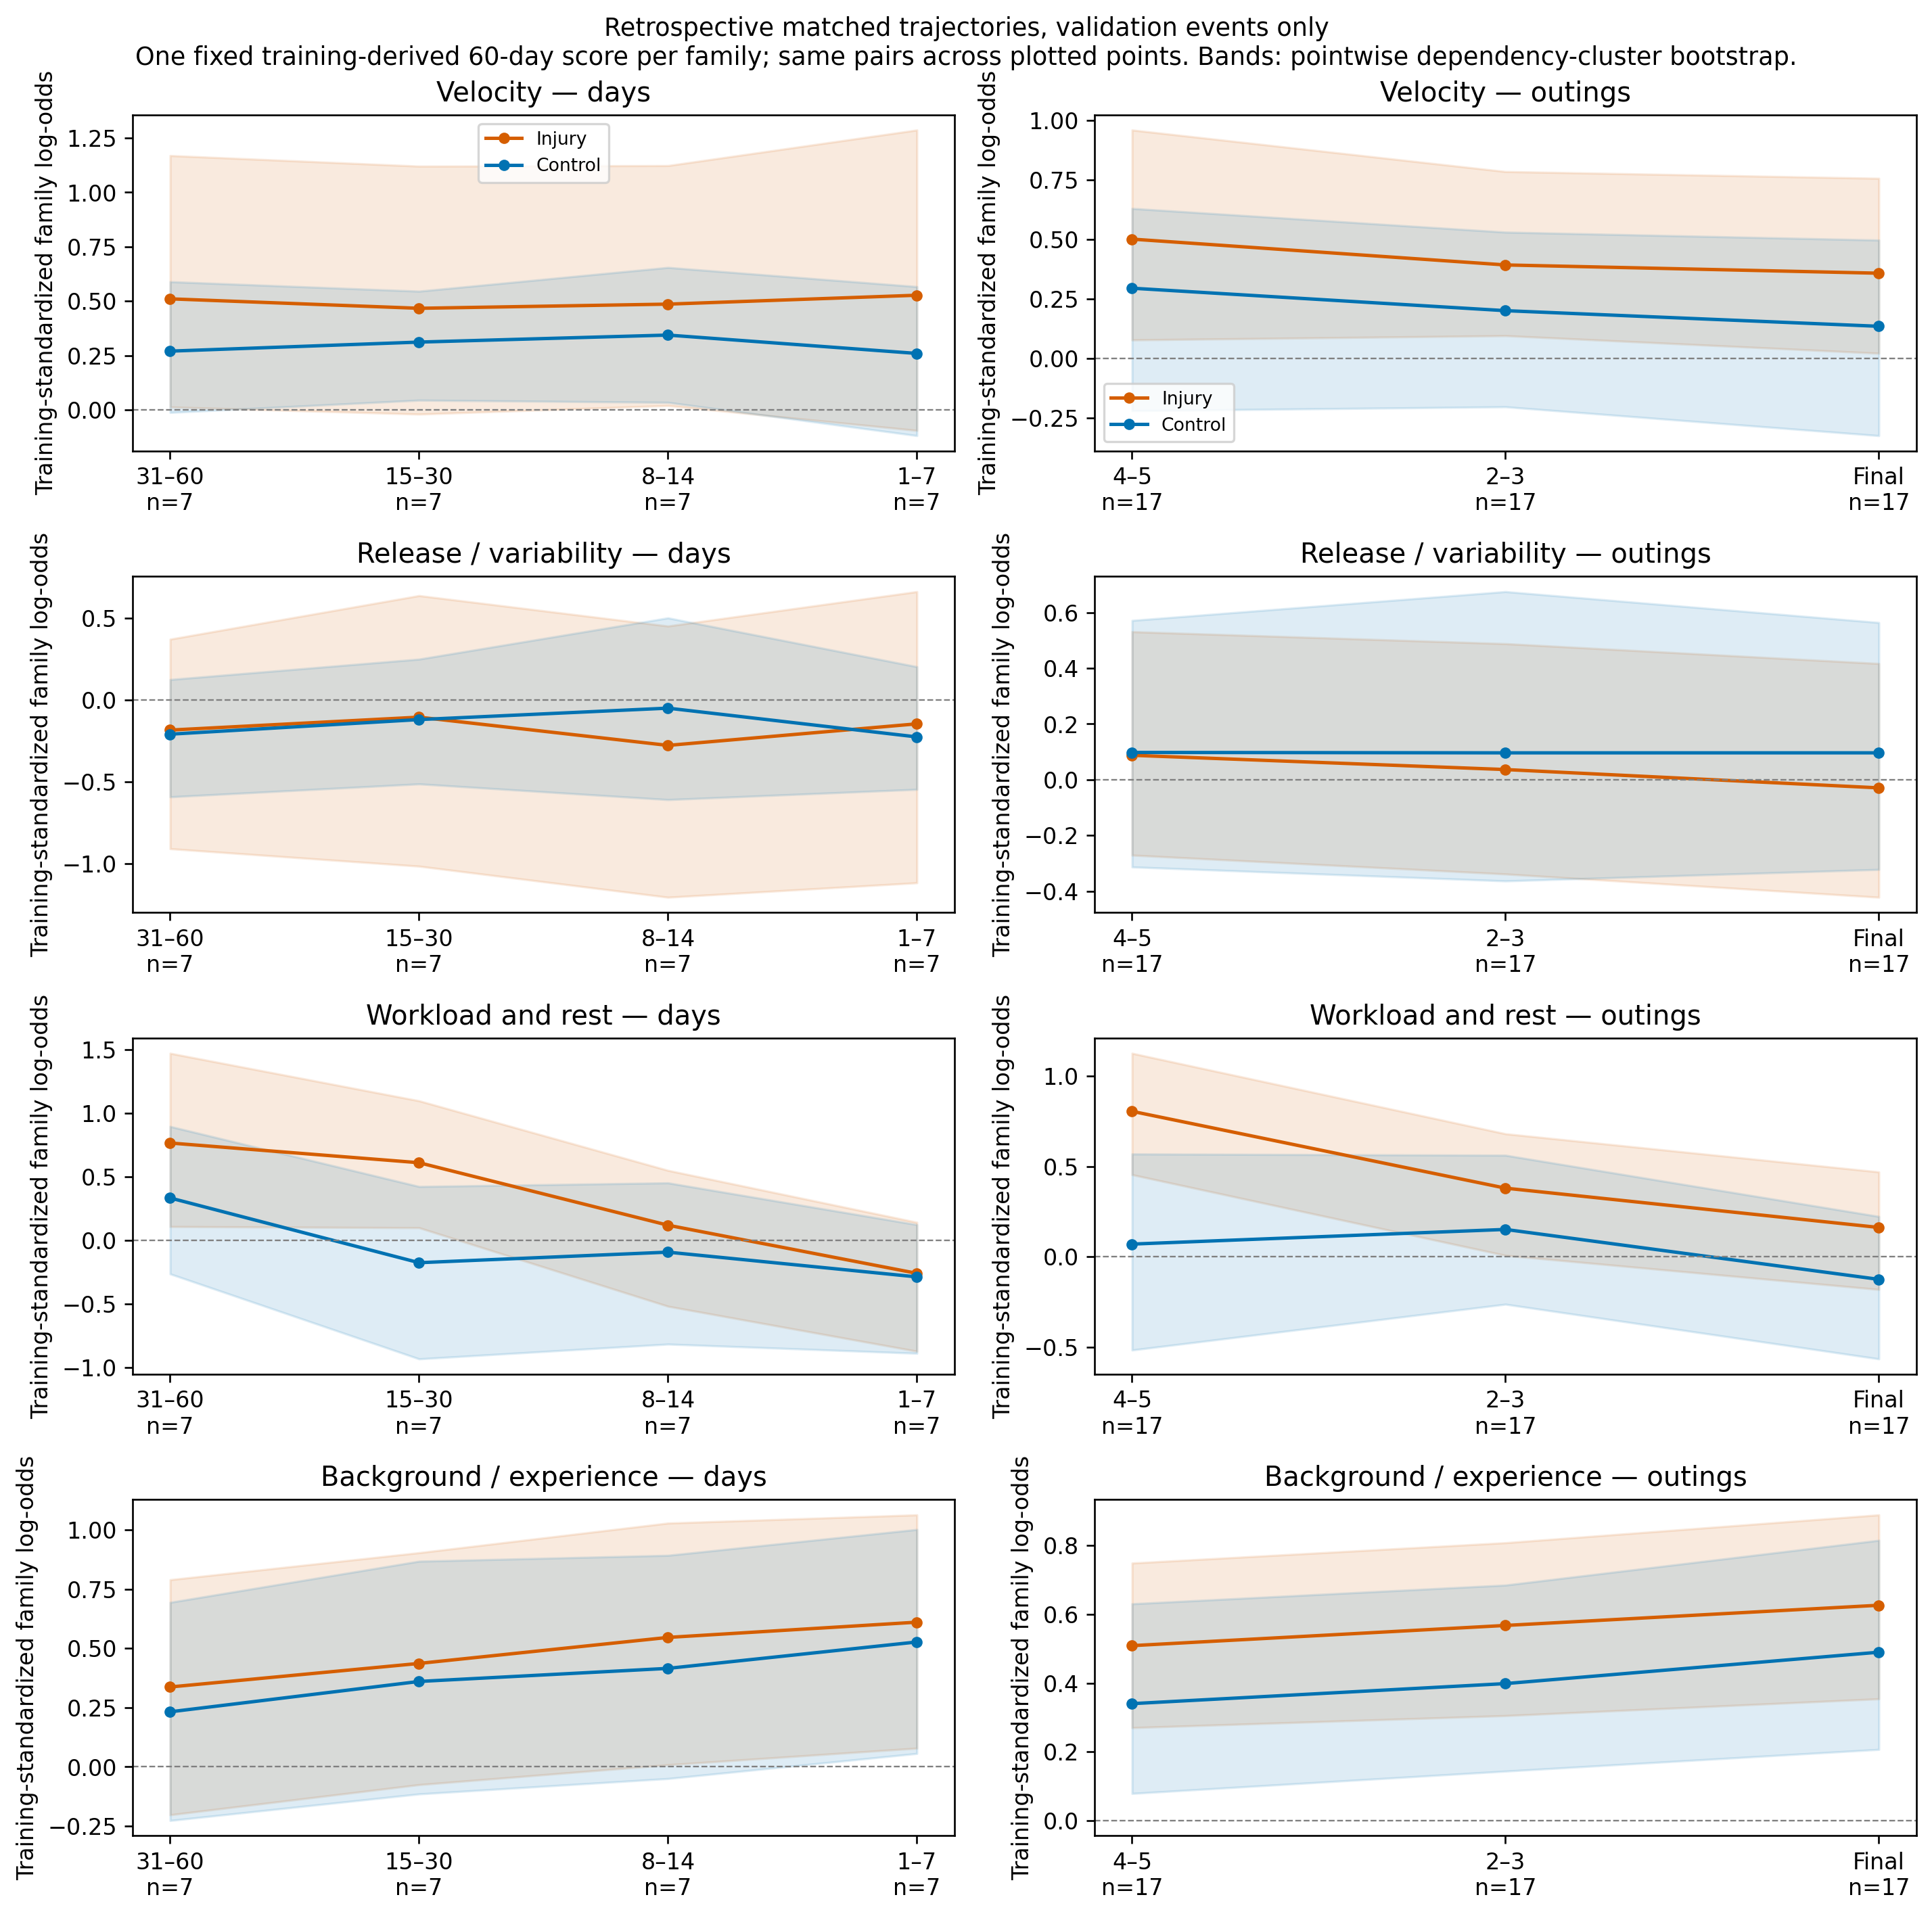

,partition,family,mode,events,dependency_clusters,final_minus_distant_difference,ci_low,ci_high,fraction_events_increasing,interpretation
0,validation,Appearance performance,calendar,7,7,0.013464,-0.654473,0.754262,0.571429,Pointwise exploratory paired contrast; no phys...
2,validation,Appearance performance,outings,17,16,-0.540874,-0.981866,-0.099565,0.352941,Pointwise exploratory paired contrast; no phys...
4,validation,Extension,calendar,7,7,0.060157,-0.495954,0.795261,0.428571,Pointwise exploratory paired contrast; no phys...
6,validation,Extension,outings,17,16,-0.063743,-0.262537,0.087394,0.470588,Pointwise exploratory paired contrast; no phys...
8,validation,Location and strike fractions,calendar,7,7,0.133181,-0.193804,0.572155,0.571429,Pointwise exploratory paired contrast; no phys...
10,validation,Location and strike fractions,outings,17,16,-0.298682,-0.809203,0.196234,0.352941,Pointwise exploratory paired contrast; no phys...
12,validation,Pitch mix and pitch-type counts,calendar,7,7,0.133127,-0.151754,0.478585,0.571429,Pointwise exploratory paired contrast; no phys...
14,validation,Pitch mix and pitch-type counts,outings,17,16,0.203557,0.042611,0.377752,0.647059,Pointwise exploratory paired contrast; no phys...
16,validation,Pitch movement,calendar,7,7,-0.120130,-0.413439,0.140343,0.571429,Pointwise exploratory paired contrast; no phys...
18,validation,Pitch movement,outings,17,16,-0.024611,-0.382327,0.288837,0.470588,Pointwise exploratory paired contrast; no phys...


In [3]:
plot('05_matched_family_trajectories')
t=read_table('trajectory_shape')
display(t.loc[t.partition.eq('validation')])

Calendar plots require the same matched pairs in all four bins. Outing plots require the same pairs in final/2–3/4–5 outings; available-pair farther-out results are retained separately. Bands are pointwise dependency-cluster bootstrap intervals, not simultaneous physiological evidence. A persistent offset is not imminent tissue damage.

In [4]:
g=read_table('trajectory_summary')
display(g.loc[g.partition.eq('validation')&g.kind.eq('difference')&g.support.eq('available_pairs')&g.family.isin(['Velocity','Workload and rest'])])

,partition,family,mode,support,point,label,kind,mean,ci_low,ci_high,events,dependency_clusters
866,validation,Velocity,calendar,available_pairs,0,31–60,difference,0.096125,-0.552060,0.797136,8,8
869,validation,Velocity,calendar,available_pairs,1,15–30,difference,0.105233,-0.442128,0.681965,16,16
872,validation,Velocity,calendar,available_pairs,2,8–14,difference,0.202066,-0.173047,0.643176,17,16
875,validation,Velocity,calendar,available_pairs,3,1–7,difference,0.443518,-0.061985,0.942180,20,19
914,validation,Velocity,outings,available_pairs,0,11+,difference,0.508741,-0.233559,1.569650,4,4
917,validation,Velocity,outings,available_pairs,1,6–10,difference,0.026642,-0.550073,0.627428,11,10
920,validation,Velocity,outings,available_pairs,2,4–5,difference,0.206149,-0.368840,0.808827,17,16
923,validation,Velocity,outings,available_pairs,3,2–3,difference,0.356601,-0.142676,0.822132,20,19
926,validation,Velocity,outings,available_pairs,4,Final,difference,0.436595,-0.079070,0.959054,20,19
962,validation,Workload and rest,calendar,available_pairs,0,31–60,difference,0.745032,0.100880,1.485911,8,8


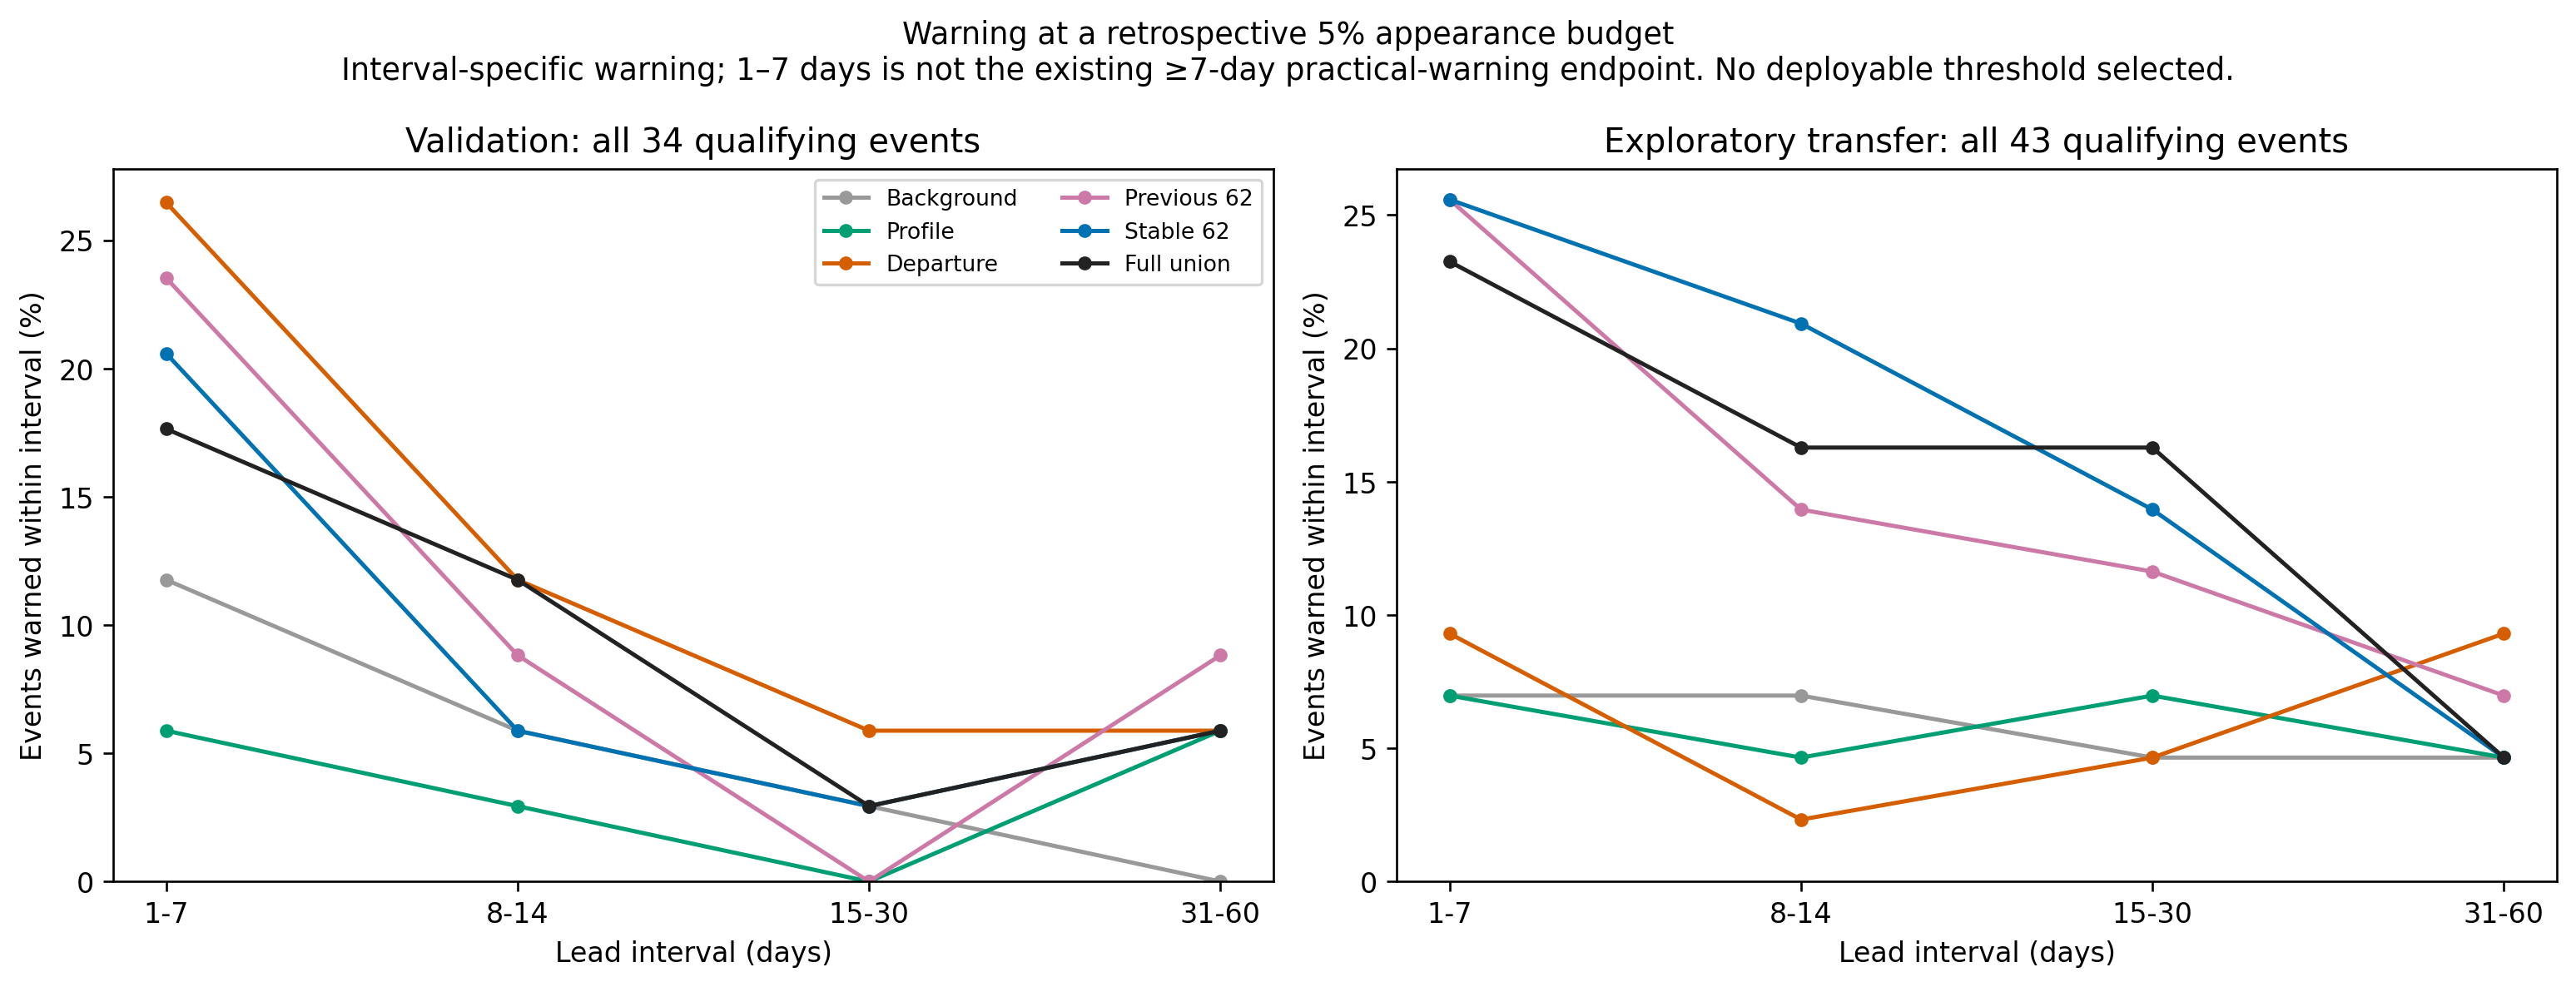

,partition,interval,model,alerted_events,qualifying_events,observable_events,alerts_per_detected_event,non_actionable_alert_fraction
48,validation,1-7,Profile,2.0,34.0,25.0,556.500000,0.996406
50,validation,1-7,Departure,9.0,34.0,25.0,123.666667,0.990117
54,validation,1-7,Stable 62,7.0,34.0,25.0,159.000000,0.991015
104,validation,8-14,Profile,1.0,34.0,20.0,1113.000000,0.998203
106,validation,8-14,Departure,4.0,34.0,20.0,278.250000,0.995508
110,validation,8-14,Stable 62,2.0,34.0,20.0,556.500000,0.997305
160,validation,15-30,Profile,0.0,34.0,17.0,NaN,1.000000
162,validation,15-30,Departure,2.0,34.0,17.0,556.500000,0.997305
166,validation,15-30,Stable 62,1.0,34.0,17.0,1113.000000,0.995508
216,validation,31-60,Profile,2.0,34.0,10.0,556.500000,0.991914


,partition,interval,model,alerted_events,qualifying_events,observable_events,alerts_per_detected_event,non_actionable_alert_fraction
24,test,1-7,Profile,3,43,28,379.666667,0.995610
25,test,1-7,Departure,4,43,28,284.750000,0.996488
27,test,1-7,Stable 62,11,43,28,103.545455,0.988586
52,test,8-14,Profile,2,43,27,569.500000,0.998244
53,test,8-14,Departure,1,43,27,1139.000000,0.999122
55,test,8-14,Stable 62,9,43,27,126.555556,0.991220
80,test,15-30,Profile,3,43,21,379.666667,0.992976
81,test,15-30,Departure,2,43,21,569.500000,0.998244
83,test,15-30,Stable 62,6,43,21,189.833333,0.989464
108,test,31-60,Profile,2,43,15,569.500000,0.996488


In [5]:
plot('06_interval_warning')
for name in ['development_metrics','transfer_metrics']:
    d=read_table(name)
    display(d.loc[d.partition.ne('train')&d.model.isin(['Departure','Profile','Stable 62']),['partition','interval','model','alerted_events','qualifying_events','observable_events','alerts_per_detected_event','non_actionable_alert_fraction']])

These are interval-specific retrospective top-5% budgets. The 1–7-day outcome includes warnings too late for the earlier ≥7-day practical target. All qualifying events remain in the denominator, including those without opportunities. No deployable threshold was selected.

In [6]:
display(Markdown((OUT/'summary.md').read_text()))

# Initial UCL temporal signal decomposition

This is development-stage signal discovery, not an independently confirmed early-warning system. The refined endpoint, source dates, frozen feature sets, chronological splits and database are unchanged.

## Design and support

Four disjoint future intervals: **1–7, 8–14, 15–30 and 31–60 days**. All primary models use the same observed 60-day first-event cohort: 64,646 training, 22,269 validation and 22,782 exploratory-transfer appearances. A known other injury ends the first-event risk interval; ambiguous outcomes remain censored. A UCL event in a different interval is a negative for the specific interval, not a healthy-pitcher designation.

| Validation interval | Positive appearances | Represented events | All qualifying events |
|---|---:|---:|---:|
| 1-7 days | 52 | 25 | 34 |
| 8-14 days | 28 | 20 | 34 |
| 15-30 days | 58 | 17 | 34 |
| 31-60 days | 51 | 10 | 34 |

The 31–60-day estimate is supported by only 10 validation events. Interval widths and event composition differ; PR lift normalizes prevalence but does not make the prediction tasks identical. All-event warning denominators include events without eligible opportunities.

The 113-field union of Background, Profile, Departure-8, Previous-62 and Stable-62 defines 11 families. Fixed C=1 logistic regression is used for all 112 interval fits. Scaling, clipping, imputation and missingness flags are training-derived. No interval boundaries, representations or regularization were tuned. Arm angle and within-outing velocity decline remain outside this long-history analysis because of prior coverage exclusions; documented prior UCL history remains excluded for unverified publication timing. Prior publicly reported IL count is included in background.

## What the estimates show

| Family/reference | 1–7d PR lift | 8–14d | 15–30d | 31–60d |
|---|---:|---:|---:|---:|
| Velocity | 10.66 | 1.25 | 1.77 | 4.86 |
| Workload and rest | 1.80 | 2.26 | 3.52 | 7.24 |
| Pitcher background and experience | 2.26 | 1.69 | 1.09 | 1.50 |
| Role and recent starts | 1.69 | 1.35 | 2.15 | 2.47 |
| Departure | 2.26 | 1.91 | 1.11 | 1.31 |
| Profile | 1.31 | 1.42 | 1.29 | 3.51 |
| Previous 62 | 11.79 | 2.08 | 1.17 | 2.08 |
| Stable 62 | 4.06 | 3.36 | 1.95 | 2.15 |

**0 of 33 predeclared family timing contrasts exclude zero under joint 95% bootstrap bands.** Point estimates alone do not establish acute, intermediate or persistent categories. Family ablation and grouped permutation sometimes disagree; the families share correlated information, and refitting after ablation can reduce overfitting. The permutation measure is marginal within-season reliance, not a conditional or causal effect.

## Event concentration and stability

- Velocity, 1-7 days: one event contributes **80.6%** of AP. Excluding that pitcher from evaluation changes AP from 0.02489 to 0.00403. This is an influence diagnostic; the event remains in the dataset.
- Workload and rest, 31-60 days: one event contributes **69.4%** of AP. Excluding that pitcher from evaluation changes AP from 0.01659 to 0.00397. This is an influence diagnostic; the event remains in the dataset.

Two families nominated using development-only mean normalized ablation loss: **Velocity, Pitcher background and experience**. These are follow-up candidates, not established temporal signals. Six common whole-pitcher training resamples preserve histories and repeat preprocessing.

| Nominated family | Interval | Positive ablation in training refits | Refit loss range (AP / prevalence) |
|---|---|---:|---:|
| Velocity | 1-7 | 5/6 | -0.03 to 1.31 |
| Velocity | 8-14 | 4/6 | -0.01 to 1.77 |
| Velocity | 15-30 | 5/6 | -0.04 to 0.26 |
| Velocity | 31-60 | 4/6 | -0.08 to 7.87 |
| Pitcher background and experience | 1-7 | 5/6 | -2.17 to 0.92 |
| Pitcher background and experience | 8-14 | 5/6 | -0.03 to 1.06 |
| Pitcher background and experience | 15-30 | 1/6 | -1.55 to 0.41 |
| Pitcher background and experience | 31-60 | 5/6 | -0.15 to 10.03 |

Only **10 validation events** have eligible opportunities in every interval. A shared-event evaluation sensitivity is saved for every family/model; it changes event composition without fitting or selecting a new model. Interval-upper-follow-up sensitivity for Full union, Profile and Departure is also retained. Neither sensitivity is a prospective validation.

## Matched trajectories and interpretation

Each family trajectory uses one fixed 60-day training-only logistic score, standardized using its training log-odds distribution. The score does not change depending on the retrospectively known lead interval. Original matched controls are reused. Calendar plots balance the same pairs across all four bins; outing plots balance final, 2–3 and 4–5 appearances. Available-pair summaries for 6–10 and 11+ outings are separate and never treated as the same calendar durations. Bootstrap clusters connect events sharing either case or control pitchers.

- calendar: 7–7 balanced events per family; 2/11 unadjusted family difference-change intervals exclude zero. These exploratory trajectory contrasts are not corrected across families.
- outings: 17–17 balanced events per family; 3/11 unadjusted family difference-change intervals exclude zero. These exploratory trajectory contrasts are not corrected across families.

Persistent case-control offsets are profile associations, not proof of an approaching injury. Score direction combines the family’s current levels, historical levels and departures; it is not a physiological latent construct. Sparse balanced support and the same previously examined cohorts limit inference about shape.

Velocity-family matched difference changes are near zero: +0.027 training-score SD in calendar alignment (95% interval −0.224 to +0.331), and +0.017 SD in outing alignment (−0.203 to +0.236). Workload-family case-control scores decrease toward the event in both alignments (−0.404 and −0.448 SD; unadjusted intervals below zero). This is not evidence of a general rise in workload risk near injury; the score blends workload level, rest and changes, and only seven calendar-balanced events contribute.

## Transfer, warning and next step

The development family choices, model signatures, interval definitions and contrast results were saved before scoring 2024–2025. All frozen families and null findings were transferred; transfer cannot redefine a candidate or claim independent confirmation. Warning comparisons use retrospective top-5% appearance budgets for each interval, not deployable thresholds. The 1–7-day endpoint is more proximal than the existing ≥7-day practical-warning objective.

Departure-8 PR lift is **2.26, 1.91, 1.11, 1.31** across validation intervals and **1.74, 1.07, 1.26, 1.47** in exploratory transfer. Its near-minus-far validation contrast is +0.95 (95% interval −0.52 to +2.94), so stronger near-term discrimination remains uncertain. Profile’s 31–60-day lift drops from **3.51** in validation to **0.90** in transfer. At the 5% budget, Departure-8 warns on 9/34 validation events at 1–7 days but 4/43 transfer events; the corresponding 8–14-day figures are 4/34 and 1/43. Broader models have stronger transfer ranking in some intervals, but this does not validate the proposed temporal family ordering.

**The temporal heterogeneity hypothesis remains unconfirmed in this first pass.** Use the nominated families only for narrow, prespecified replication questions. Do not launch flexible lag searches or freeze an acute/intermediate/chronic physiological narrative from these heatmaps. Freeze the interval definitions and family mapping for a genuinely post-freeze chronological cohort, and improve event/timing support before escalating model complexity.

See [methods](../../docs/ucl_temporal_methods.md), [notebooks](../../notebooks/ucl_temporal/README.md), `tables/family_matrix_validation.csv`, `tables/temporal_contrasts_validation.csv`, `tables/followup_sensitivity.csv`, and `tables/shared_event_sensitivity_validation.csv`.


In [7]:
from src.injury_analysis.ucl_temporal_reporting import validate
checks=validate()
display(pd.Series({'checks':len(checks),'passed':sum(x['passed'] for x in checks)}))

Verified checkpoint: data


checks    156
passed    156
dtype: int64

The first pass does not establish a reproducible acute/intermediate/longer-horizon ordering. Freeze definitions and test narrow hypotheses on a genuinely future chronological cohort. More flexible temporal models should follow adequate event support and replication, not the largest exploratory cell.